In [13]:
from pathlib import Path
import pandas as pd

# Locate project root automatically
root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src" / "netids").is_dir()
    ),
    None
)

if root is None:
    raise FileNotFoundError("Project root not found.")

ctu_path = (
    root / "data" / "raw" / "ctu-13"
    / "capture20110815-2.binetflow"
)

if not ctu_path.is_file():
    raise FileNotFoundError(ctu_path)

ctu_raw = pd.read_csv(ctu_path, low_memory=False)
ctu_raw.columns = ctu_raw.columns.str.strip()

labels = ctu_raw["Label"].astype("string").str.strip()

is_botnet = labels.str.contains(
    "Botnet", case=False, regex=False, na=False
)
is_normal = labels.str.contains(
    "Normal", case=False, regex=False, na=False
)
is_background = labels.str.contains(
    "Background", case=False, regex=False, na=False
)

match_count = (
    is_botnet.astype(int)
    + is_normal.astype(int)
    + is_background.astype(int)
)

if not match_count.eq(1).all():
    raise ValueError("Ambiguous or unmatched labels detected.")

# Use verified Normal and Botnet records only
protocol = ctu_raw["Proto"].astype(str).str.lower()

mask = (
    protocol.isin(["tcp", "udp"])
    & (is_normal | is_botnet)
)

columns = [
    "StartTime", "SrcAddr", "DstAddr",
    "Proto", "Dur", "TotPkts", "TotBytes"
]

labeled = ctu_raw.loc[mask, columns].copy()
labeled["target"] = is_botnet.loc[mask].astype(int)

labeled["StartTime"] = pd.to_datetime(
    labeled["StartTime"], errors="raise"
)

numeric_cols = ["Dur", "TotPkts", "TotBytes"]

for col in numeric_cols:
    labeled[col] = pd.to_numeric(
        labeled[col], errors="raise"
    )

if (
    labeled[numeric_cols].isna().any().any()
    or (labeled[numeric_cols] < 0).any().any()
):
    raise ValueError("Invalid core numeric features.")

labeled = (
    labeled.sort_values("StartTime")
    .reset_index(drop=True)
)

print("=== LOCAL TRAINING DATASET ===")
print("Project:", root)
print("Original records:", len(ctu_raw))
print("Labeled TCP/UDP records:", len(labeled))

print("\n=== TARGET DISTRIBUTION ===")
print("Normal (0):", (labeled["target"] == 0).sum())
print("Botnet (1):", (labeled["target"] == 1).sum())

print("\n=== DATASET RANGE ===")
print(labeled["StartTime"].min())
print(labeled["StartTime"].max())


=== LOCAL TRAINING DATASET ===
Project: D:\suricata-ai-project
Original records: 129832
Labeled TCP/UDP records: 5577

=== TARGET DISTRIBUTION ===
Normal (0): 4676
Botnet (1): 901

=== DATASET RANGE ===
2011-08-15 16:43:20.937998
2011-08-15 17:13:24.058003


In [14]:

import numpy as np
import pandas as pd

# Build candidate feature matrix
X = pd.DataFrame({
    "protocol_tcp": (
        labeled["Proto"].str.lower() == "tcp"
    ).astype(int),

    "duration_log": np.log1p(labeled["Dur"]),

    "packets_log": np.log1p(labeled["TotPkts"]),

    "bytes_log": np.log1p(labeled["TotBytes"])
})

y = labeled["target"].astype(int)

if not np.isfinite(X.to_numpy()).all():
    raise ValueError("Non-finite transformed features.")

# Chronological holdout
split_idx = int(len(labeled) * 0.70)

X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()

y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

train_meta = labeled.iloc[:split_idx].copy()
test_meta = labeled.iloc[split_idx:].copy()

print("=== TEMPORAL SPLIT ===")
print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\n=== CLASS DISTRIBUTION ===")
print("Train labels:")
print(y_train.value_counts().sort_index())

print("\nTest labels:")
print(y_test.value_counts().sort_index())

print("\n=== TIME RANGE ===")
print("Train:", train_meta["StartTime"].min(),
      "to", train_meta["StartTime"].max())
print("Test:", test_meta["StartTime"].min(),
      "to", test_meta["StartTime"].max())

print("\n=== SOURCE IP OVERLAP ===")
train_ips = set(train_meta["SrcAddr"].astype(str))
test_ips = set(test_meta["SrcAddr"].astype(str))
print("Shared source IPs:", len(train_ips & test_ips))

# Stop if time split cannot evaluate both classes
if set(y_train.unique()) != {0, 1}:
    raise ValueError(
        "Training set does not contain both classes."
    )

if set(y_test.unique()) != {0, 1}:
    raise ValueError(
        "Test set does not contain both classes."
    )

print("\nTemporal split validation: PASS")


=== TEMPORAL SPLIT ===
Train: (3903, 4)
Test: (1674, 4)

=== CLASS DISTRIBUTION ===
Train labels:
target
0    3673
1     230
Name: count, dtype: int64

Test labels:
target
0    1003
1     671
Name: count, dtype: int64

=== TIME RANGE ===
Train: 2011-08-15 16:43:20.937998 to 2011-08-15 17:01:00.835086
Test: 2011-08-15 17:01:00.835099 to 2011-08-15 17:13:24.058003

=== SOURCE IP OVERLAP ===
Shared source IPs: 5

Temporal split validation: PASS


In [15]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    average_precision_score
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    )
}

results = []
trained_models = {}

def evaluate_model(name, pred, scores=None):
    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    tcp_mask = test_meta["Proto"].str.lower().eq("tcp")

    row = {
        "Model": name,
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "Balanced Acc": balanced_accuracy_score(
            y_test, pred
        ),
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
        "TCP F1": f1_score(
            y_test.loc[tcp_mask],
            pred[tcp_mask.to_numpy()],
            zero_division=0
        ),
        "PR-AUC": (
            average_precision_score(y_test, scores)
            if scores is not None else np.nan
        )
    }

    results.append(row)

    print(f"\n=== {name} ===")
    print("Confusion matrix:", [[tn, fp], [fn, tp]])
    print("Precision:", round(row["Precision"], 4))
    print("Recall:", round(row["Recall"], 4))
    print("F1:", round(row["F1"], 4))

# Simple protocol-only reference
tcp_rule = X_test["protocol_tcp"].to_numpy()

evaluate_model("TCP-only rule", tcp_rule)

# Train actual ML models
for name, model in models.items():
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    scores = model.predict_proba(X_test)[:, 1]

    trained_models[name] = model
    evaluate_model(name, pred, scores)

print("\n=== MODEL COMPARISON ===")
comparison = pd.DataFrame(results)
display(comparison.round(4))

print("\n=== TEST BOTNET PREVALENCE ===")
print(round(y_test.mean(), 4))



=== TCP-only rule ===
Confusion matrix: [[np.int64(682), np.int64(321)], [np.int64(30), np.int64(641)]]
Precision: 0.6663
Recall: 0.9553
F1: 0.7851

=== Logistic Regression ===
Confusion matrix: [[np.int64(738), np.int64(265)], [np.int64(31), np.int64(640)]]
Precision: 0.7072
Recall: 0.9538
F1: 0.8122

=== Random Forest ===
Confusion matrix: [[np.int64(992), np.int64(11)], [np.int64(86), np.int64(585)]]
Precision: 0.9815
Recall: 0.8718
F1: 0.9234

=== MODEL COMPARISON ===


,Model,Precision,Recall,F1,Balanced Acc,FPR,TCP F1,PR-AUC
0,TCP-only rule,0.6663,0.9553,0.7851,0.8176,0.3200,0.7998,NaN
1,Logistic Regression,0.7072,0.9538,0.8122,0.8448,0.2642,0.8279,0.5458
2,Random Forest,0.9815,0.8718,0.9234,0.9304,0.0110,0.9448,0.9703



=== TEST BOTNET PREVALENCE ===
0.4008


- Random Forest đang cho kết quả tốt nhất trong ba phương pháp bạn thử. Đây là cột mốc đáng kể: pipeline huấn luyện ML đầu tiên đã chạy thành công trên máy Windows của bạn.

- Tuy nhiên, trước khi lưu mô hình và phát triển Deep Learning, chúng ta cần kiểm tra liệu kết quả này có phản ánh đúng khả năng phát hiện Botnet hay chỉ phù hợp với dữ liệu CTU-13 hiện tại.

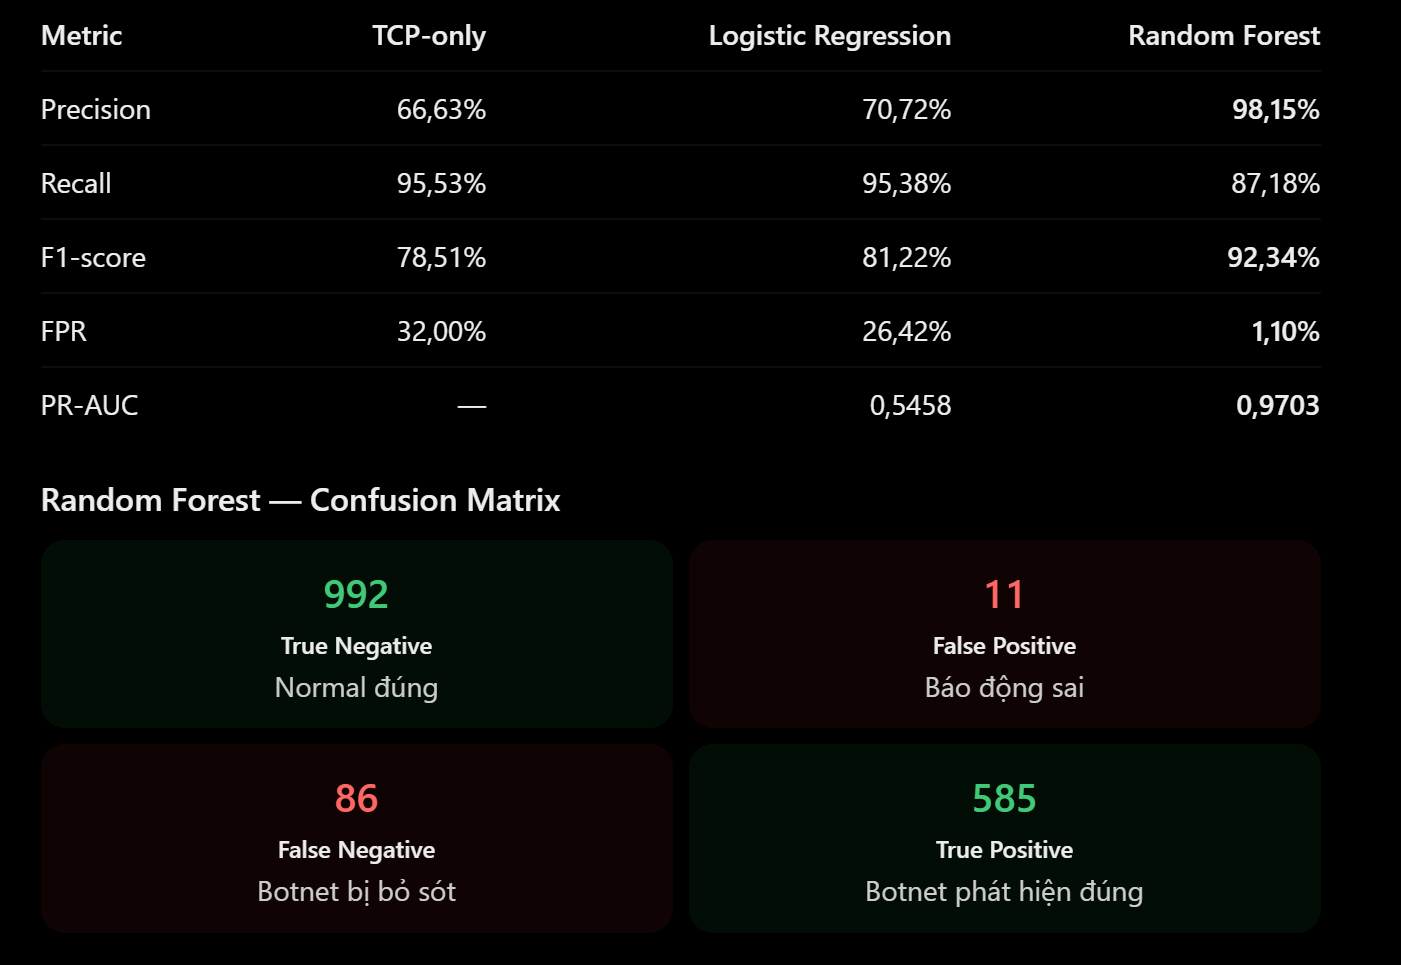

- Random Forest phát hiện được 585/671 Flow Botnet và chỉ cảnh báo sai 11/1.003 Flow Normal.

- Điểm quan trọng: mô hình đạt Precision cao nhưng bỏ sót 86 Flow Botnet. Với IDS, False Negative vẫn rất đáng quan tâm.

### Có một vấn đề lớn về phân phối Train/ Test

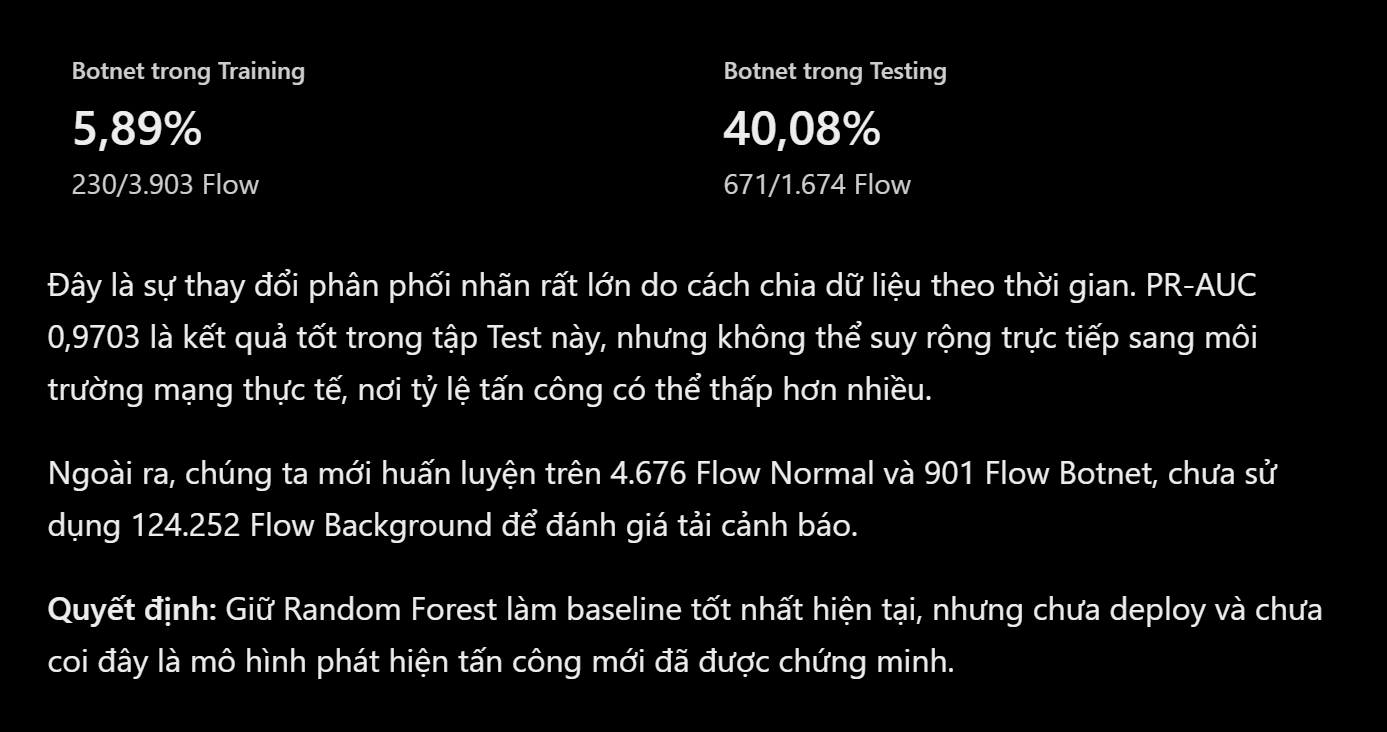

In [17]:
# Protocol Error Analysis

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

rf = trained_models["Random Forest"]

protocol_results = []

for proto in ["tcp", "udp"]:
    mask = (
        test_meta["Proto"]
        .astype(str)
        .str.lower()
        .eq(proto)
    )

    X_part = X_test.loc[mask]
    y_part = y_test.loc[mask]

    if len(X_part) == 0:
        continue

    pred = rf.predict(X_part)

    tn, fp, fn, tp = confusion_matrix(
        y_part, pred, labels=[0, 1]
    ).ravel()

    protocol_results.append({
        "Protocol": proto.upper(),
        "Records": len(y_part),
        "Botnet": int(y_part.sum()),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision_score(
            y_part, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_part, pred, zero_division=0
        ),
        "F1": f1_score(
            y_part, pred, zero_division=0
        ),
        "FPR": (
            fp / (fp + tn)
            if fp + tn > 0 else np.nan
        )
    })

protocol_report = pd.DataFrame(protocol_results)

print("=== RANDOM FOREST BY PROTOCOL ===")
display(protocol_report.round(4))

print("\n=== FEATURE IMPORTANCE ===")

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values(
    "Importance", ascending=False
)

display(importance.reset_index(drop=True))

print("\n=== SOURCE IP OVERLAP ===")

train_ips = set(
    train_meta["SrcAddr"].astype(str)
)

shared = (
    test_meta["SrcAddr"]
    .astype(str)
    .isin(train_ips)
)

print("Shared source IP records:", shared.sum())
print("Share of test records (%):",
      round(shared.mean() * 100, 2))

print("Botnet records with shared source IP:",
      int(y_test.loc[shared].sum()))


=== RANDOM FOREST BY PROTOCOL ===


,Protocol,Records,Botnet,TP,FP,FN,TN,Precision,Recall,F1,FPR
0,TCP,962,641,582,9,59,312,0.9848,0.908,0.9448,0.0280
1,UDP,712,30,3,2,27,680,0.6000,0.100,0.1714,0.0029



=== FEATURE IMPORTANCE ===


,Feature,Importance
0,duration_log,0.614031
1,bytes_log,0.168094
2,protocol_tcp,0.122915
3,packets_log,0.094959



=== SOURCE IP OVERLAP ===
Shared source IP records: 1668
Share of test records (%): 99.64
Botnet records with shared source IP: 671


Lưu ý: feature_importances_ của Random Forest chỉ cung cấp mức đóng góp tương đối theo cơ chế chia nhánh của mô hình. Nó chưa chứng minh quan hệ nhân quả hoặc độ tin cậy của từng feature.

In [18]:
# Background Alert Stress Test

import numpy as np
import pandas as pd

rf = trained_models["Random Forest"]

labels = ctu_raw["Label"].astype("string")
proto = ctu_raw["Proto"].astype(str).str.lower()

background_mask = (
    labels.str.contains(
        "Background",
        case=False,
        regex=False,
        na=False
    )
    & proto.isin(["tcp", "udp"])
)

bg = ctu_raw.loc[background_mask].copy()

for col in ["Dur", "TotPkts", "TotBytes"]:
    bg[col] = pd.to_numeric(bg[col], errors="coerce")

valid = (
    bg[["Dur", "TotPkts", "TotBytes"]]
    .notna().all(axis=1)
    & np.isfinite(
        bg[["Dur", "TotPkts", "TotBytes"]]
        .to_numpy(dtype=float)
    ).all(axis=1)
    & (
        bg[["Dur", "TotPkts", "TotBytes"]] >= 0
    ).all(axis=1)
)

print("Excluded invalid records:", (~valid).sum())

bg = bg.loc[valid].copy()

X_bg = pd.DataFrame({
    "protocol_tcp": (
        bg["Proto"].str.lower() == "tcp"
    ).astype(int),
    "duration_log": np.log1p(bg["Dur"]),
    "packets_log": np.log1p(bg["TotPkts"]),
    "bytes_log": np.log1p(bg["TotBytes"])
}, index=bg.index)

X_bg = X_bg[X_train.columns]

bg["botnet_score"] = rf.predict_proba(X_bg)[:, 1]
bg["alert"] = rf.predict(X_bg).astype(bool)

print("=== BACKGROUND ALERT STRESS TEST ===")
print("Total Background flows:", len(bg))
print("Flagged flows:", bg["alert"].sum())
print("Alert rate (%):",
      round(bg["alert"].mean() * 100, 3))

print("\n=== ALERTS BY PROTOCOL ===")

report = (
    bg.groupby("Proto")["alert"]
    .agg(["count", "sum", "mean"])
)

report.columns = [
    "Records",
    "Flagged",
    "AlertRate"
]

report["AlertRate"] *= 100
display(report.round(3))

print("\n=== SCORE DISTRIBUTION ===")

display(
    bg["botnet_score"]
    .quantile([0, .25, .50, .75, .90, .95, .99, 1])
    .to_frame("BotnetScore")
)

print("\nIMPORTANT:")
print(
    "Background alert rate is NOT "
    "a false positive rate."
)



Excluded invalid records: 0
=== BACKGROUND ALERT STRESS TEST ===
Total Background flows: 121862
Flagged flows: 7357
Alert rate (%): 6.037

=== ALERTS BY PROTOCOL ===


,Records,Flagged,AlertRate
Proto,,,
tcp,29354,5501,18.740
udp,92508,1856,2.006



=== SCORE DISTRIBUTION ===


,BotnetScore
0.00,0.000000
0.25,0.009132
0.50,0.017154
0.75,0.168010
0.90,0.332109
0.95,0.562589
0.99,0.953790
1.00,1.000000



IMPORTANT:
Background alert rate is NOT a false positive rate.


#### Cell code phía trên mục đích:
- Đây là bước quan trọng nhất trước khi quyết định có giữ Random Forest làm baseline triển khai.
- Chúng ta sẽ lấy 121.862 Flow Background TCP/UDP và đưa qua mô hình đã huấn luyện, không gán Background thành Normal hoặc Botnet.
- Mục tiêu chỉ là đo xem mô hình sẽ đưa ra bao nhiêu cảnh báo khi gặp dữ liệu chưa có nhãn tin cậy.

Không gọi những cảnh báo này là False Positive -> Vì Background chưa được xác minh là lưu lượng bình thường. Những Flow bị mô hình đánh dấu có thể là bất thường thực sự, cũng có thể là sai lệch giữa nguồn dữ liệu.

### Phân tích theo kết quả:

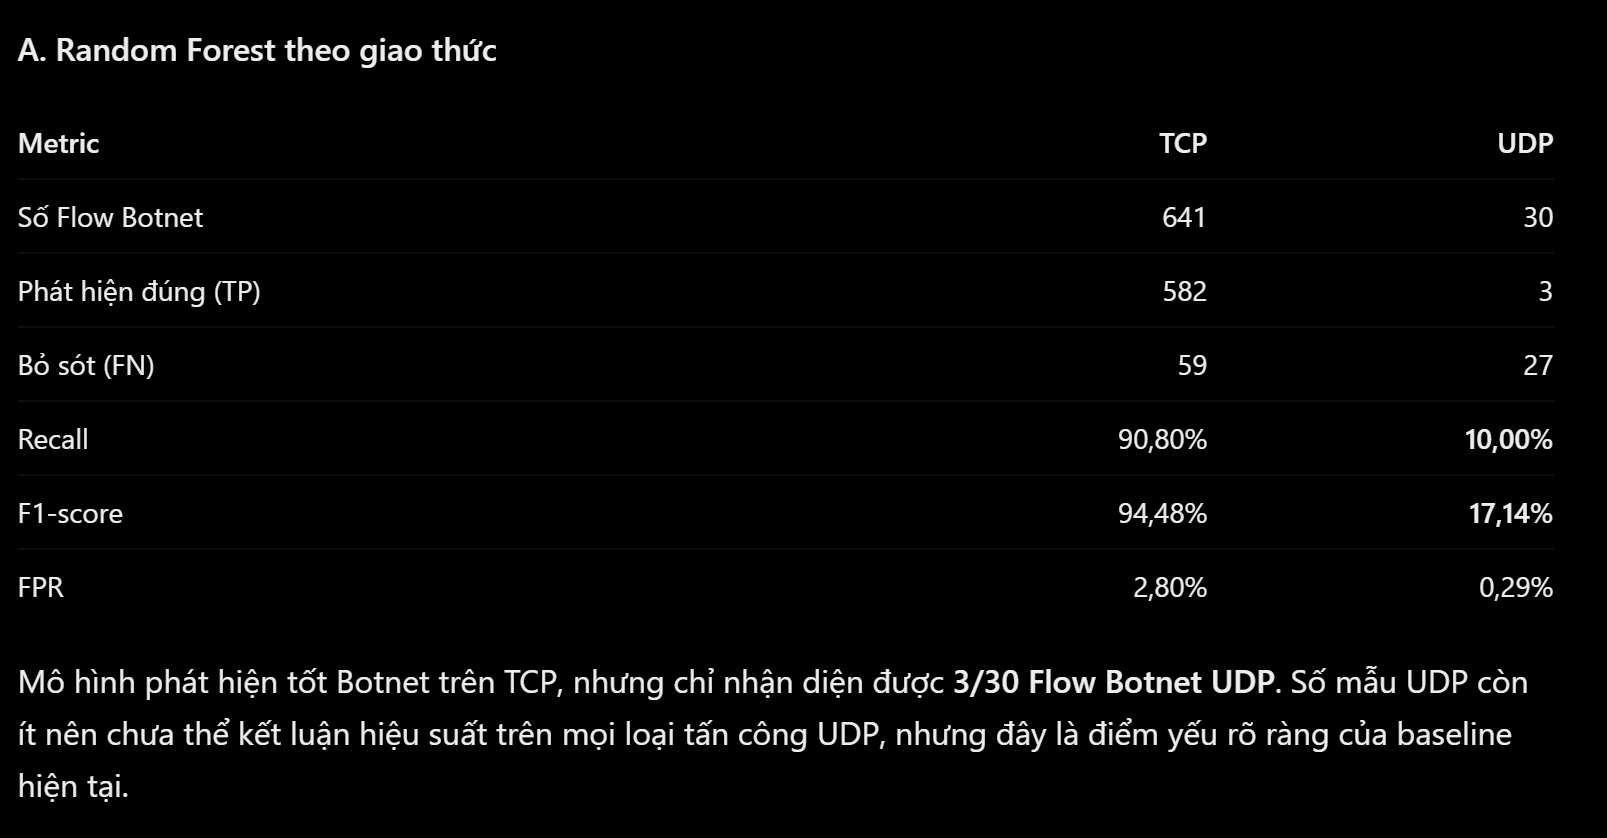

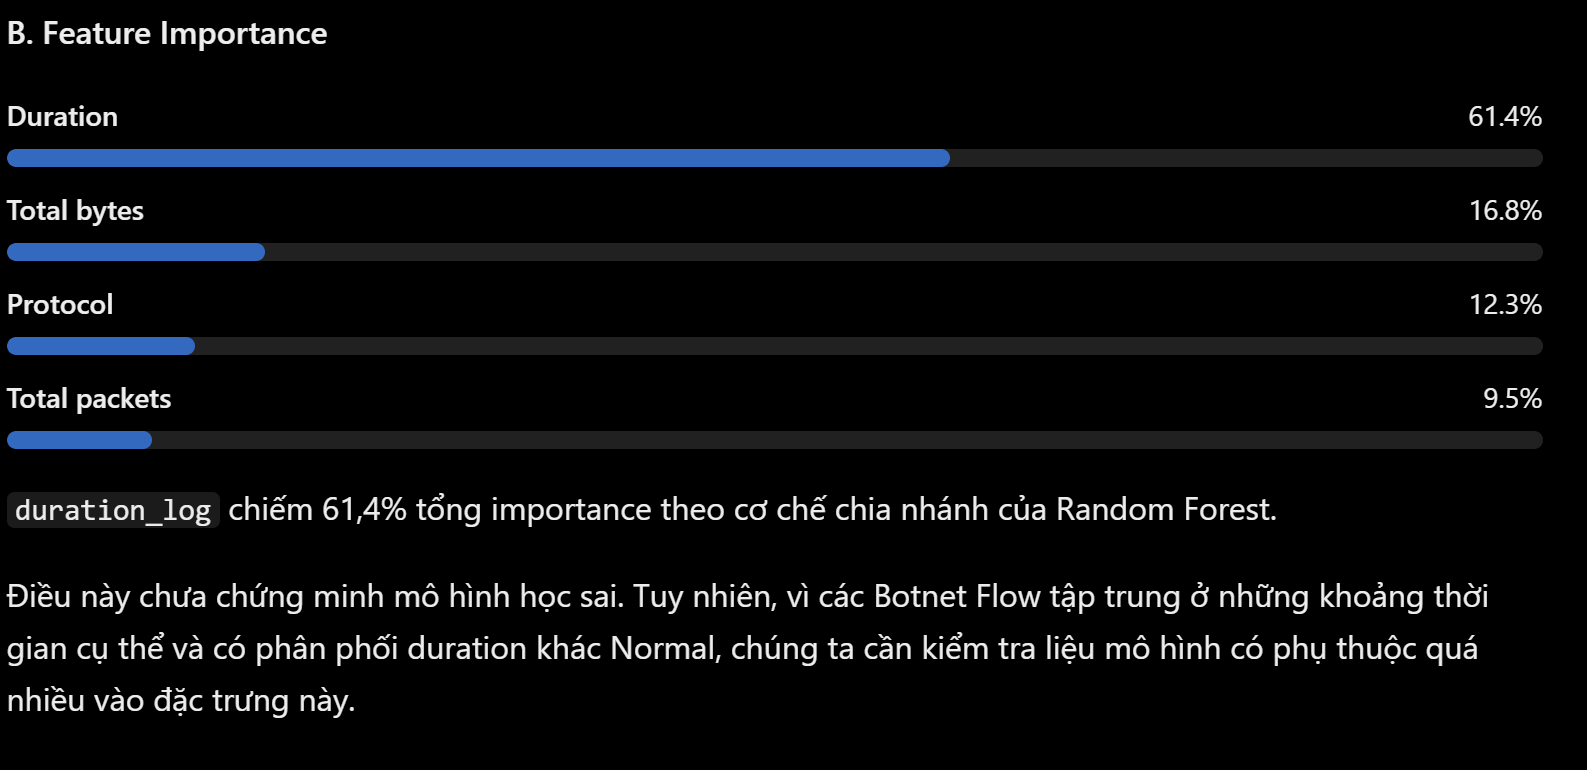

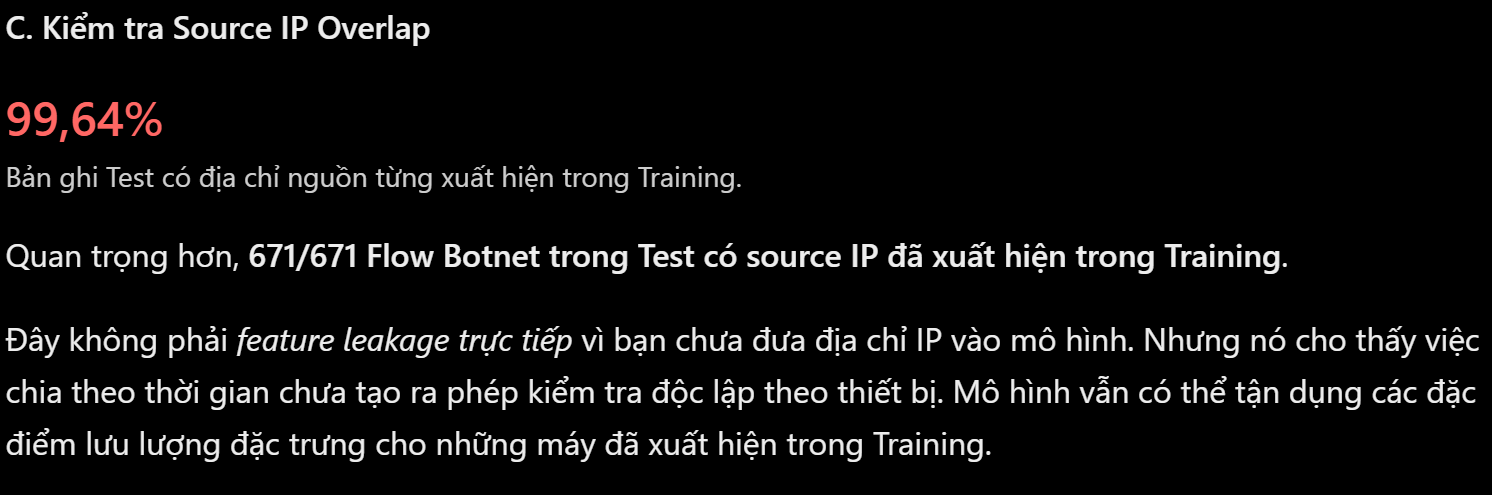

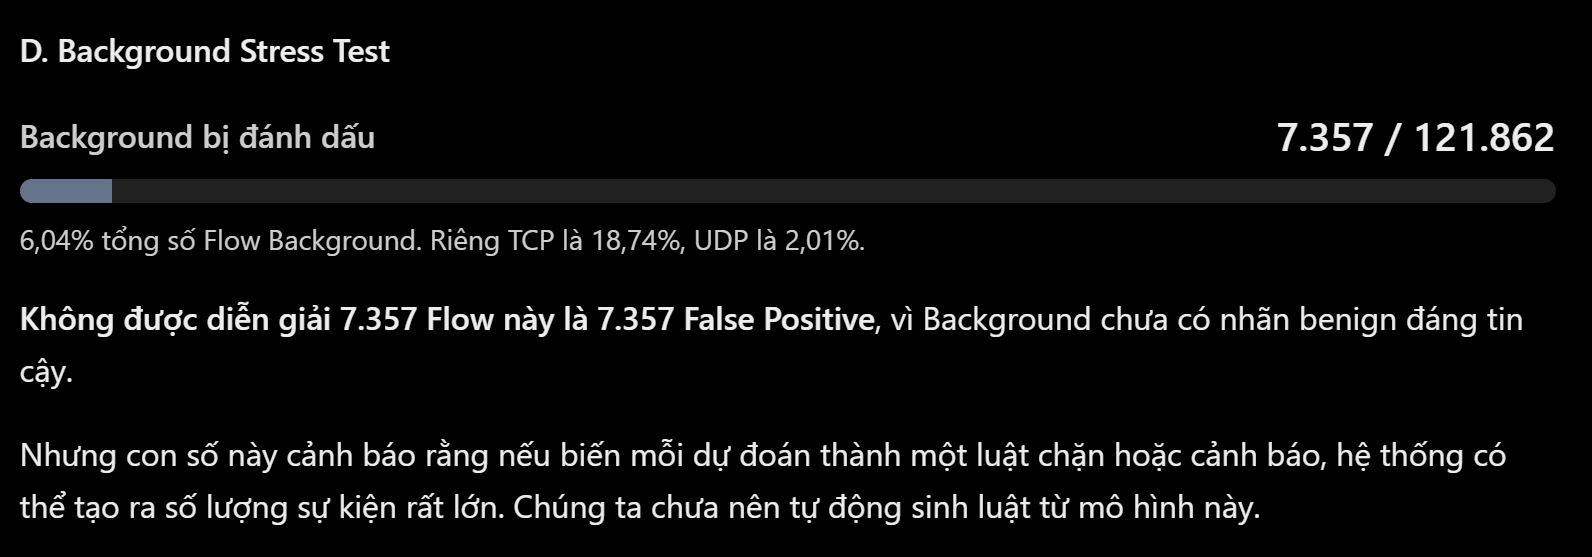

In [19]:
# Kiểm tra mức độ phụ thuộc vào Source IP

import pandas as pd

print("=== SOURCE HOST GENERALIZATION AUDIT ===")

train_sources_all = set(
    train_meta["SrcAddr"].astype(str)
)

rows = []

for label, name in [(0, "Normal"), (1, "Botnet")]:
    train_part = train_meta[
        train_meta["target"] == label
    ]

    test_part = test_meta[
        test_meta["target"] == label
    ]

    train_ips = set(
        train_part["SrcAddr"].astype(str)
    )

    test_ips = set(
        test_part["SrcAddr"].astype(str)
    )

    test_src = test_part["SrcAddr"].astype(str)

    rows.append({
        "Class": name,
        "Train flows": len(train_part),
        "Test flows": len(test_part),
        "Train unique IPs": len(train_ips),
        "Test unique IPs": len(test_ips),
        "Shared same-class IPs": len(train_ips & test_ips),
        "Test flows seen in train class": int(
            test_src.isin(train_ips).sum()
        ),
        "Test flows seen in train overall": int(
            test_src.isin(train_sources_all).sum()
        )
    })

host_report = pd.DataFrame(rows)
display(host_report)

print("\n=== GENERALIZATION DIAGNOSTIC ===")

botnet_train_hosts = set(
    train_meta.loc[
        train_meta["target"] == 1, "SrcAddr"
    ].astype(str)
)

botnet_test_hosts = set(
    test_meta.loc[
        test_meta["target"] == 1, "SrcAddr"
    ].astype(str)
)

unseen_botnet_hosts = (
    botnet_test_hosts - botnet_train_hosts
)

print("Unseen Botnet source hosts:",
      len(unseen_botnet_hosts))

if len(unseen_botnet_hosts) == 0:
    print(
        "LIMITATION: No independent Botnet "
        "source host is available for testing."
    )
else:
    print(
        "Some Botnet hosts are unseen. "
        "Host-level evaluation may be feasible."
    )

"""
- Kết quả này sẽ xác định liệu tập dữ liệu có đủ thiết bị độc lập để kiểm tra khả năng tổng quát hóa theo host hay không.
- Nếu chỉ có một nguồn Botnet trong kịch bản này, chúng ta không thể chứng minh khả năng phát hiện trên Botnet host mới chỉ bằng cách chia lại các Flow.
"""

=== SOURCE HOST GENERALIZATION AUDIT ===


,Class,Train flows,Test flows,Train unique IPs,Test unique IPs,Shared same-class IPs,Test flows seen in train class,Test flows seen in train overall
0,Normal,3673,1003,19,7,4,997,997
1,Botnet,230,671,1,1,1,671,671



=== GENERALIZATION DIAGNOSTIC ===
Unseen Botnet source hosts: 0
LIMITATION: No independent Botnet source host is available for testing.


'\n- Kết quả này sẽ xác định liệu tập dữ liệu có đủ thiết bị độc lập để kiểm tra khả năng tổng quát hóa theo host hay không.\n- Nếu chỉ có một nguồn Botnet trong kịch bản này, chúng ta không thể chứng minh khả năng phát hiện trên Botnet host mới chỉ bằng cách chia lại các Flow.\n'

In [20]:
# Feature Ablation Experiment: Thí nghiệm loại bỏ đặc điểm

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    recall_score,
    confusion_matrix,
    average_precision_score
)

feature_sets = {
    "Full baseline": [
        "protocol_tcp",
        "duration_log",
        "packets_log",
        "bytes_log"
    ],
    "Without duration": [
        "protocol_tcp",
        "packets_log",
        "bytes_log"
    ],
    "Without protocol": [
        "duration_log",
        "packets_log",
        "bytes_log"
    ],
    "Packets + bytes": [
        "packets_log",
        "bytes_log"
    ]
}

ablation_results = []
ablation_models = {}

for name, columns in feature_sets.items():

    if name == "Full baseline":
        model = trained_models["Random Forest"]
    else:
        model = RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            X_train[columns],
            y_train
        )

    scores = model.predict_proba(
        X_test[columns]
    )[:, 1]

    pred = (scores >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    proto = (
        test_meta["Proto"]
        .astype(str)
        .str.lower()
    )

    tcp_mask = proto.eq("tcp")
    udp_mask = proto.eq("udp")

    ablation_results.append({
        "Feature Set": name,
        "F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "FPR": fp / (fp + tn),
        "PR-AUC": average_precision_score(
            y_test, scores
        ),
        "TCP Recall": recall_score(
            y_test.loc[tcp_mask],
            pred[tcp_mask.to_numpy()],
            zero_division=0
        ),
        "UDP Recall": recall_score(
            y_test.loc[udp_mask],
            pred[udp_mask.to_numpy()],
            zero_division=0
        )
    })

    ablation_models[name] = model

print("=== FEATURE ABLATION RESULTS ===")

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

print("\nNOTE:")
print(
    "This is exploratory evaluation on an "
    "already-used holdout, not final validation."
)

"""
    Chúng ta sẽ kiểm tra Random Forest còn hoạt động tốt đến đâu nếu bỏ duration_log hoặc protocol_tcp.
    Đây là một phép kiểm tra độ nhạy của mô hình, không phải huấn luyện phiên bản production.
"""

=== FEATURE ABLATION RESULTS ===


,Feature Set,F1,Recall,FPR,PR-AUC,TCP Recall,UDP Recall
0,Full baseline,0.9234,0.8718,0.0110,0.9703,0.9080,0.1000
1,Without duration,0.8733,0.8063,0.0269,0.9439,0.8393,0.1000
2,Without protocol,0.9165,0.8510,0.0040,0.9701,0.8861,0.1000
3,Packets + bytes,0.8643,0.7928,0.0279,0.9234,0.8081,0.4667



NOTE:
This is exploratory evaluation on an already-used holdout, not final validation.


'\n    Chúng ta sẽ kiểm tra Random Forest còn hoạt động tốt đến đâu nếu bỏ duration_log hoặc protocol_tcp.\n    Đây là một phép kiểm tra độ nhạy của mô hình, không phải huấn luyện phiên bản production.\n'

In [21]:

import sys
import numpy as np
import pandas as pd
from pathlib import Path

# root was defined in Cell 1
src_path = str(root / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from netids.adapters.ctu import (
    prepare_ctu13_flows,
    MODEL_FEATURES,
)

ctu_features = prepare_ctu13_flows(ctu_raw)

print("=== CTU-13 ADAPTER VALIDATION ===")

print("Total TCP/UDP flows:", len(ctu_features))

print("\n=== LABEL DISTRIBUTION ===")
display(
    ctu_features["label_group"]
    .value_counts()
    .to_frame("Records")
)

print("\n=== MODEL FEATURES ===")
print(MODEL_FEATURES)

print("\n=== FEATURE CHECKS ===")

assert len(ctu_features) == 127439

counts = ctu_features["label_group"].value_counts()

assert counts["Background"] == 121862
assert counts["Normal"] == 4676
assert counts["Botnet"] == 901

background = (
    ctu_features["label_group"] == "Background"
)

assert ctu_features.loc[
    background, "target"
].isna().all()

normal = ctu_features["label_group"] == "Normal"
botnet = ctu_features["label_group"] == "Botnet"

assert ctu_features.loc[
    normal, "target"
].eq(0).all()

assert ctu_features.loc[
    botnet, "target"
].eq(1).all()

X_adapter = ctu_features[list(MODEL_FEATURES)]

assert not X_adapter.isna().any().any()
assert np.isfinite(
    X_adapter.to_numpy(dtype=float)
).all()

print("\n=== RESULT ===")
print("PASS: CTU-13 Adapter validated.")
print("Background labels preserved as unknown.")
print("No original data modified.")


=== CTU-13 ADAPTER VALIDATION ===
Total TCP/UDP flows: 127439

=== LABEL DISTRIBUTION ===


,Records
label_group,
Background,121862
Normal,4676
Botnet,901



=== MODEL FEATURES ===
('protocol_tcp', 'duration_log', 'packets_log', 'bytes_log')

=== FEATURE CHECKS ===

=== RESULT ===
PASS: CTU-13 Adapter validated.
Background labels preserved as unknown.
No original data modified.


In [22]:
from netids.features.schema import (
    validate_feature_matrix,
    validate_ctu_labels,
    SCHEMA_VERSION,
)

X_valid = validate_feature_matrix(ctu_features)

validate_ctu_labels(ctu_features)

print("=== FEATURE CONTRACT INTEGRATION ===")
print("Schema version:", SCHEMA_VERSION)
print("Records:", len(X_valid))
print("Features:", X_valid.columns.tolist())

print("\n=== RESULT ===")
print("PASS: CTU-13 Adapter + Feature Schema integration")

=== FEATURE CONTRACT INTEGRATION ===
Schema version: flow_features_v0.1
Records: 127439
Features: ['protocol_tcp', 'duration_log', 'packets_log', 'bytes_log']

=== RESULT ===
PASS: CTU-13 Adapter + Feature Schema integration


In [23]:
# Kiểm tra pipeline với dữ liệu Training thật

import numpy as np

from netids.models.ml import make_ml_pipeline
from netids.features.schema import FEATURE_COLUMNS
from netids.adapters.ctu import MODEL_FEATURES

print("=== MODEL PIPELINE REPRODUCIBILITY ===")

assert tuple(FEATURE_COLUMNS) == tuple(MODEL_FEATURES), (
    "Adapter and feature contract are inconsistent."
)

rf_pipeline = make_ml_pipeline(
    "random_forest",
    random_state=42
)

rf_pipeline.fit(X_train, y_train)

# Compare predictions on training data only
old_rf = trained_models["Random Forest"]

old_pred = old_rf.predict(X_train)
new_pred = rf_pipeline.predict(X_train)

agreement = np.mean(old_pred == new_pred)

print("Training records:", len(X_train))
print("Prediction agreement:", round(agreement, 6))

np.testing.assert_array_equal(old_pred, new_pred)

print("\n=== RESULT ===")
print("PASS: ML pipeline reproduces previous RF.")
print("No test-set evaluation performed.")


=== MODEL PIPELINE REPRODUCIBILITY ===
Training records: 3903
Prediction agreement: 1.0

=== RESULT ===
PASS: ML pipeline reproduces previous RF.
No test-set evaluation performed.


In [31]:
import numpy as np

from netids.models.artifacts import load_ml_artifact

print("=== MODEL ARTIFACT REVALIDATION ===")

models_root = root / "artifacts" / "models"

candidates = [
    models_root / "ctu13_rf_dev_v0_1",
    models_root / "ctu13_rf_dev_v0_1_run_02",
]

expected_probs = rf_pipeline.predict_proba(X_train)
expected_labels = rf_pipeline.predict(X_train)

validated_artifact = None
loaded_pipeline = None
loaded_metadata = None

for path in candidates:
    if not path.is_dir():
        continue

    print(f"\nChecking: {path.name}")

    try:
        model, metadata = load_ml_artifact(path)

        if metadata["training_records"] != len(y_train):
            raise ValueError("Training record count mismatch")

        if metadata["model_name"] != "random_forest":
            raise ValueError("Unexpected model type")

        restored_probs = model.predict_proba(X_train)
        restored_labels = model.predict(X_train)

        max_abs_diff = np.max(
            np.abs(expected_probs - restored_probs)
        )

        # Floating-point tolerance
        np.testing.assert_allclose(
            expected_probs,
            restored_probs,
            rtol=1e-12,
            atol=1e-12,
        )

        # Predicted classes must remain identical
        np.testing.assert_array_equal(
            expected_labels,
            restored_labels,
        )

        validated_artifact = path
        loaded_pipeline = model
        loaded_metadata = metadata

        print("Max absolute difference:", max_abs_diff)
        print("Probability comparison: PASS")
        print("Predicted labels: IDENTICAL")
        break

    except Exception as exc:
        print("Validation failed:", type(exc).__name__)
        print(str(exc))

if validated_artifact is None:
    raise RuntimeError("No valid model artifact found")

print("\n=== FINAL ARTIFACT STATUS ===")
print("Artifact:", validated_artifact)
print("Model:", loaded_metadata["model_name"])
print("Schema:", loaded_metadata["schema_version"])
print("Training records:", loaded_metadata["training_records"])
print("SHA256:", loaded_metadata["model_sha256"])

print("\nPASS: MODEL ARTIFACT VALIDATED")
print("Status: DEVELOPMENT ONLY")

=== MODEL ARTIFACT REVALIDATION ===

Checking: ctu13_rf_dev_v0_1
Max absolute difference: 3.3306690738754696e-16
Probability comparison: PASS
Predicted labels: IDENTICAL

=== FINAL ARTIFACT STATUS ===
Artifact: D:\suricata-ai-project\artifacts\models\ctu13_rf_dev_v0_1
Model: random_forest
Schema: flow_features_v0.1
Training records: 3903
SHA256: af38e4bff09458fa39a8dc7540321c75718fcae57079c5eab2899ce18890d11c

PASS: MODEL ARTIFACT VALIDATED
Status: DEVELOPMENT ONLY
